# DSCI 552 — Homework 6

**Name:** Gina Mao  
**GitHub Username:** ruoxuanm116  
**USC ID:** 8885483334

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score,
                             accuracy_score, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.ensemble import BalancedRandomForestClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
SEED = 552
np.random.seed(SEED)

## 1. Tree-Based Methods
### (a) Download the APS Failure data
The data were downloaded from the UCI repository and stored in `../data/`. The first 20 lines of each CSV are a license header, and missing values are coded as `na`.

In [2]:
TRAIN_PATH = "../data/aps_failure_training_set.csv"
TEST_PATH = "../data/aps_failure_test_set.csv"

train_raw = pd.read_csv(TRAIN_PATH, skiprows=20, na_values="na")
test_raw = pd.read_csv(TEST_PATH, skiprows=20, na_values="na")

print("Train shape:", train_raw.shape)
print("Test shape :", test_raw.shape)
train_raw.head()

Train shape: (60000, 171)
Test shape : (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,ag_008,ag_009,ah_000,ai_000,aj_000,ak_000,al_000,am_0,an_000,ao_000,...,dq_000,dr_000,ds_000,dt_000,du_000,dv_000,dx_000,dy_000,dz_000,ea_000,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0,3664156.0,1007684.0,25896.0,0.0,2551696.0,0.0,0.0,0.0,0.0,0.0,4933296.0,3655166.0,...,0.0,0.0,202710.0,37928.0,14745580.0,1876644.0,0.0,0.0,0.0,0.0,2801180.0,2445.80,2712.0,965866.0,1706908.0,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0,1720800.0,516724.0,31642.0,0.0,1393352.0,0.0,68.0,0.0,0.0,0.0,2560898.0,2127150.0,...,0.0,0.0,103330.0,16254.0,4510080.0,868538.0,0.0,0.0,0.0,0.0,3477820.0,2211.76,2334.0,664504.0,824154.0,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0,1883374.0,292936.0,12016.0,0.0,1234132.0,0.0,0.0,0.0,0.0,0.0,2371990.0,2173634.0,...,0.0,0.0,65772.0,10534.0,300240.0,48028.0,0.0,0.0,0.0,0.0,1040120.0,1018.64,1020.0,262032.0,453378.0,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,2212.0,3232.0,1872.0,0.0,0.0,0.0,2668.0,0.0,0.0,0.0,642.0,3894.0,10184.0,7554.0,...,2014.0,370.0,48.0,18.0,15740.0,1822.0,20174.0,44.0,0.0,0.0,0.0,1.08,54.0,5670.0,1566.0,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,43752.0,1966618.0,1800340.0,131646.0,4588.0,0.0,1974038.0,0.0,226.0,0.0,0.0,0.0,3230626.0,2618878.0,...,0.0,0.0,149474.0,35154.0,457040.0,80482.0,98334.0,27588.0,0.0,0.0,21173050.0,1116.06,1176.0,404740.0,904230.0,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation
#### (b) i. Techniques for missing values (data imputation)

Commonly used techniques:

1. **Deletion**: listwise deletion (drop rows with any missing value) or dropping features with a very high missing rate. Simple, but it throws away a lot of data and can bias the result when the data are not missing completely at random (MCAR).
2. **Simple statistical imputation**: replace missing values with the feature's **mean**, **median**, or **mode** (or a constant such as 0). Fast. Median is robust to the heavy-tailed, skewed features in this data set.
3. **Indicator (missingness flag) method**: add a binary column marking whether a value was missing, together with simple imputation, so the model can use the missingness pattern itself.
4. **k-Nearest-Neighbors imputation**: fill a missing value with the (weighted) average of that feature among the *k* most similar rows.
5. **Regression / model-based imputation**: predict each missing feature from the other features (e.g., regression, random forest — *missForest*).
6. **Multiple imputation (MICE)**: iteratively model each feature conditional on the others, produce several imputed data sets, and pool the results to account for imputation uncertainty.
7. **Models that handle missing values natively**: e.g., XGBoost learns a default split direction for missing values.

**Chosen method: median imputation.** The features are counters and histogram bins with extreme skew and outliers, so the median is more representative than the mean. KNN and MICE are very expensive on 60,000 × 170. Following the footnote in the assignment, the training set is imputed with the training medians and the test set is imputed with the **test-set** medians, so no training statistics are used on the test data.

Rows with at least one missing value (train): 59409 / 60000
Overall fraction of missing cells (train): 0.0833

Top 10 features by missing rate:
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
cr_000    0.772
ab_000    0.772
bn_000    0.733
bm_000    0.659
bl_000    0.455
bk_000    0.384
dtype: float64


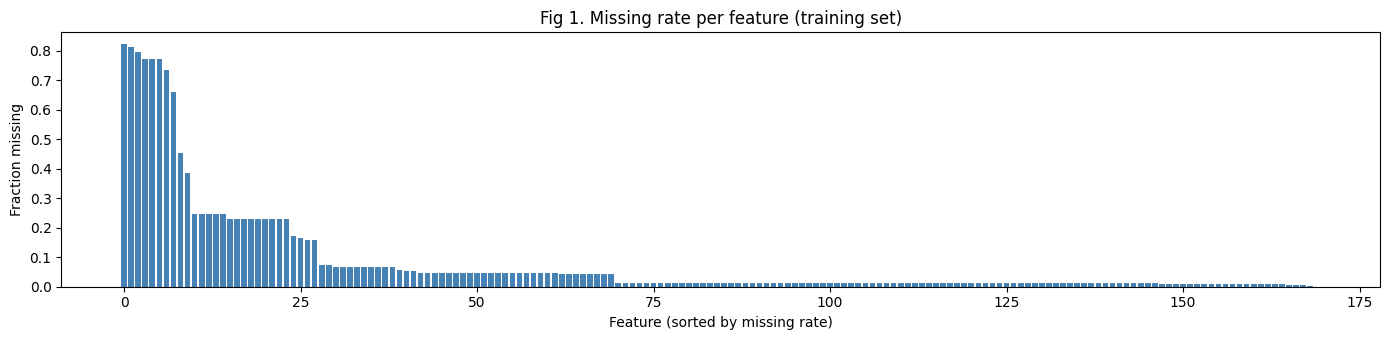

In [3]:
X_train_raw = train_raw.drop(columns="class")
X_test_raw = test_raw.drop(columns="class")
y_train = (train_raw["class"] == "pos").astype(int).values
y_test = (test_raw["class"] == "pos").astype(int).values
features = X_train_raw.columns.tolist()

miss_rate = X_train_raw.isna().mean().sort_values(ascending=False)
print(f"Rows with at least one missing value (train): {X_train_raw.isna().any(axis=1).sum()} / {len(X_train_raw)}")
print(f"Overall fraction of missing cells (train): {X_train_raw.isna().values.mean():.4f}")
print("\nTop 10 features by missing rate:")
print(miss_rate.head(10).round(3))

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(range(len(miss_rate)), miss_rate.values, color="steelblue")
ax.set_xlabel("Feature (sorted by missing rate)")
ax.set_ylabel("Fraction missing")
ax.set_title("Fig 1. Missing rate per feature (training set)")
plt.tight_layout(); plt.show()

In [4]:
# Median imputation: training set uses its own medians, test set uses the test medians (per footnote 1)
X_train = X_train_raw.fillna(X_train_raw.median())
X_test = X_test_raw.fillna(X_test_raw.median())
print("Remaining NaNs - train:", X_train.isna().sum().sum(), "| test:", X_test.isna().sum().sum())

Remaining NaNs - train: 0 | test: 0


#### (b) ii. Coefficient of variation $CV = s/m$ for each of the 170 features

In [5]:
cv = (X_train.std(ddof=1) / X_train.mean())
cv_df = cv.rename("CV").to_frame().sort_values("CV", ascending=False)
print("Note: cd_000 is constant (s = 0), so its CV is 0.")
print(f"Number of features: {len(cv_df)}")
cv_df.T

Note: cd_000 is constant (s = 0), so its CV is 0.
Number of features: 170


,cf_000,co_000,ad_000,cs_009,dh_000,dj_000,ag_000,as_000,ay_009,ak_000,az_009,ch_000,au_000,cr_000,ay_001,df_000,dz_000,ef_000,cs_008,aj_000,eg_000,dl_000,ay_002,dg_000,ay_000,...,ah_000,ac_000,bg_000,ce_000,ao_000,an_000,dt_000,do_000,cs_006,dp_000,cs_000,cv_000,dc_000,bs_000,ca_000,cb_000,bl_000,bm_000,bn_000,bk_000,bo_000,bp_000,bq_000,br_000,cd_000
CV,244.887517,244.507385,244.322816,237.930554,123.216097,117.494225,92.917755,87.3325,84.733735,80.424975,77.838544,77.453857,68.882751,58.078072,52.824714,52.292814,51.332228,49.366659,48.102206,44.265996,42.481747,39.739088,39.248654,38.486162,37.428285,...,2.311735,2.310241,2.30931,2.271205,2.270678,2.249995,2.191925,2.16607,2.142639,2.022316,1.880908,1.83721,1.725222,1.050793,0.93179,0.909183,0.871161,0.849217,0.836041,0.819602,0.792383,0.753392,0.718534,0.689112,0.0


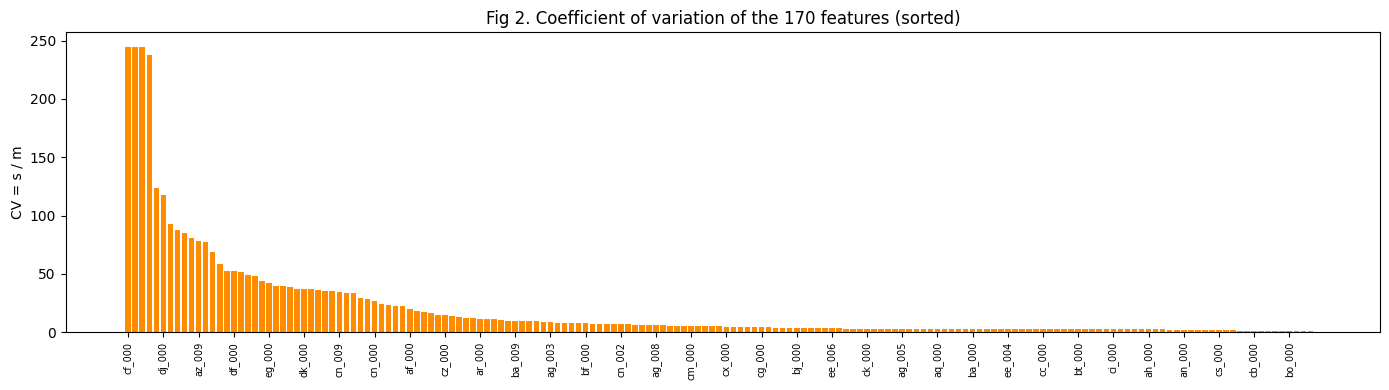

In [6]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(len(cv_df)), cv_df["CV"].values, color="darkorange")
ax.set_xticks(range(0, len(cv_df), 5))
ax.set_xticklabels(cv_df.index[::5], rotation=90, fontsize=7)
ax.set_ylabel("CV = s / m")
ax.set_title("Fig 2. Coefficient of variation of the 170 features (sorted)")
plt.tight_layout(); plt.show()

#### (b) iii. Correlation matrix

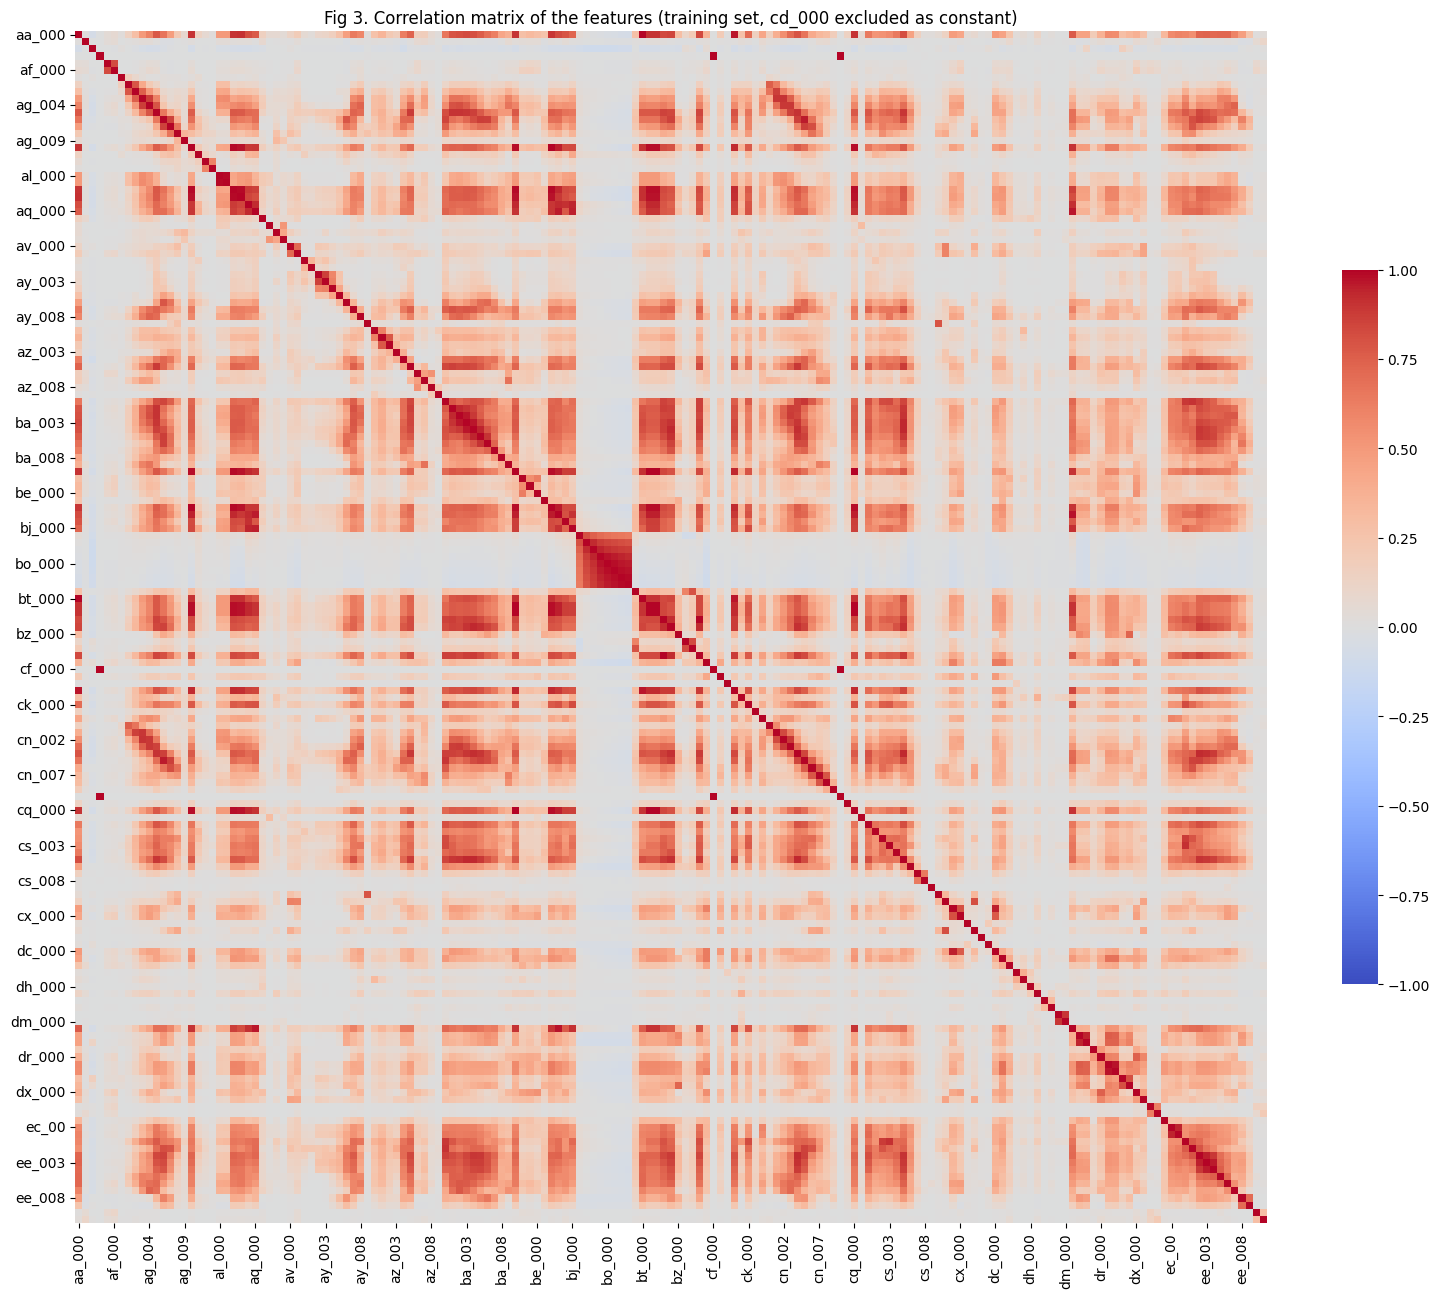

Feature pairs with |corr| > 0.9: 130 of 14196


In [7]:
corr = X_train.drop(columns=["cd_000"]).corr()   # cd_000 is constant -> correlation undefined
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, square=True,
            xticklabels=5, yticklabels=5, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Fig 3. Correlation matrix of the features (training set, cd_000 excluded as constant)")
plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(f"Feature pairs with |corr| > 0.9: {(upper.abs() > 0.9).sum()} of {len(upper)}")

#### (b) iv. The $\lfloor\sqrt{170}\rfloor = 13$ features with the highest CV: scatter plots and box plots
The scatter-plot matrix uses a random sample of 3,000 points (stratified, so the 1.67 % positive rate is kept) so it is readable. Both plots use a log(1+x) scale, because the features span many orders of magnitude and on the raw scale almost all points collapse onto the axes. The box plots use the full training set.

k = 13; top-CV features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


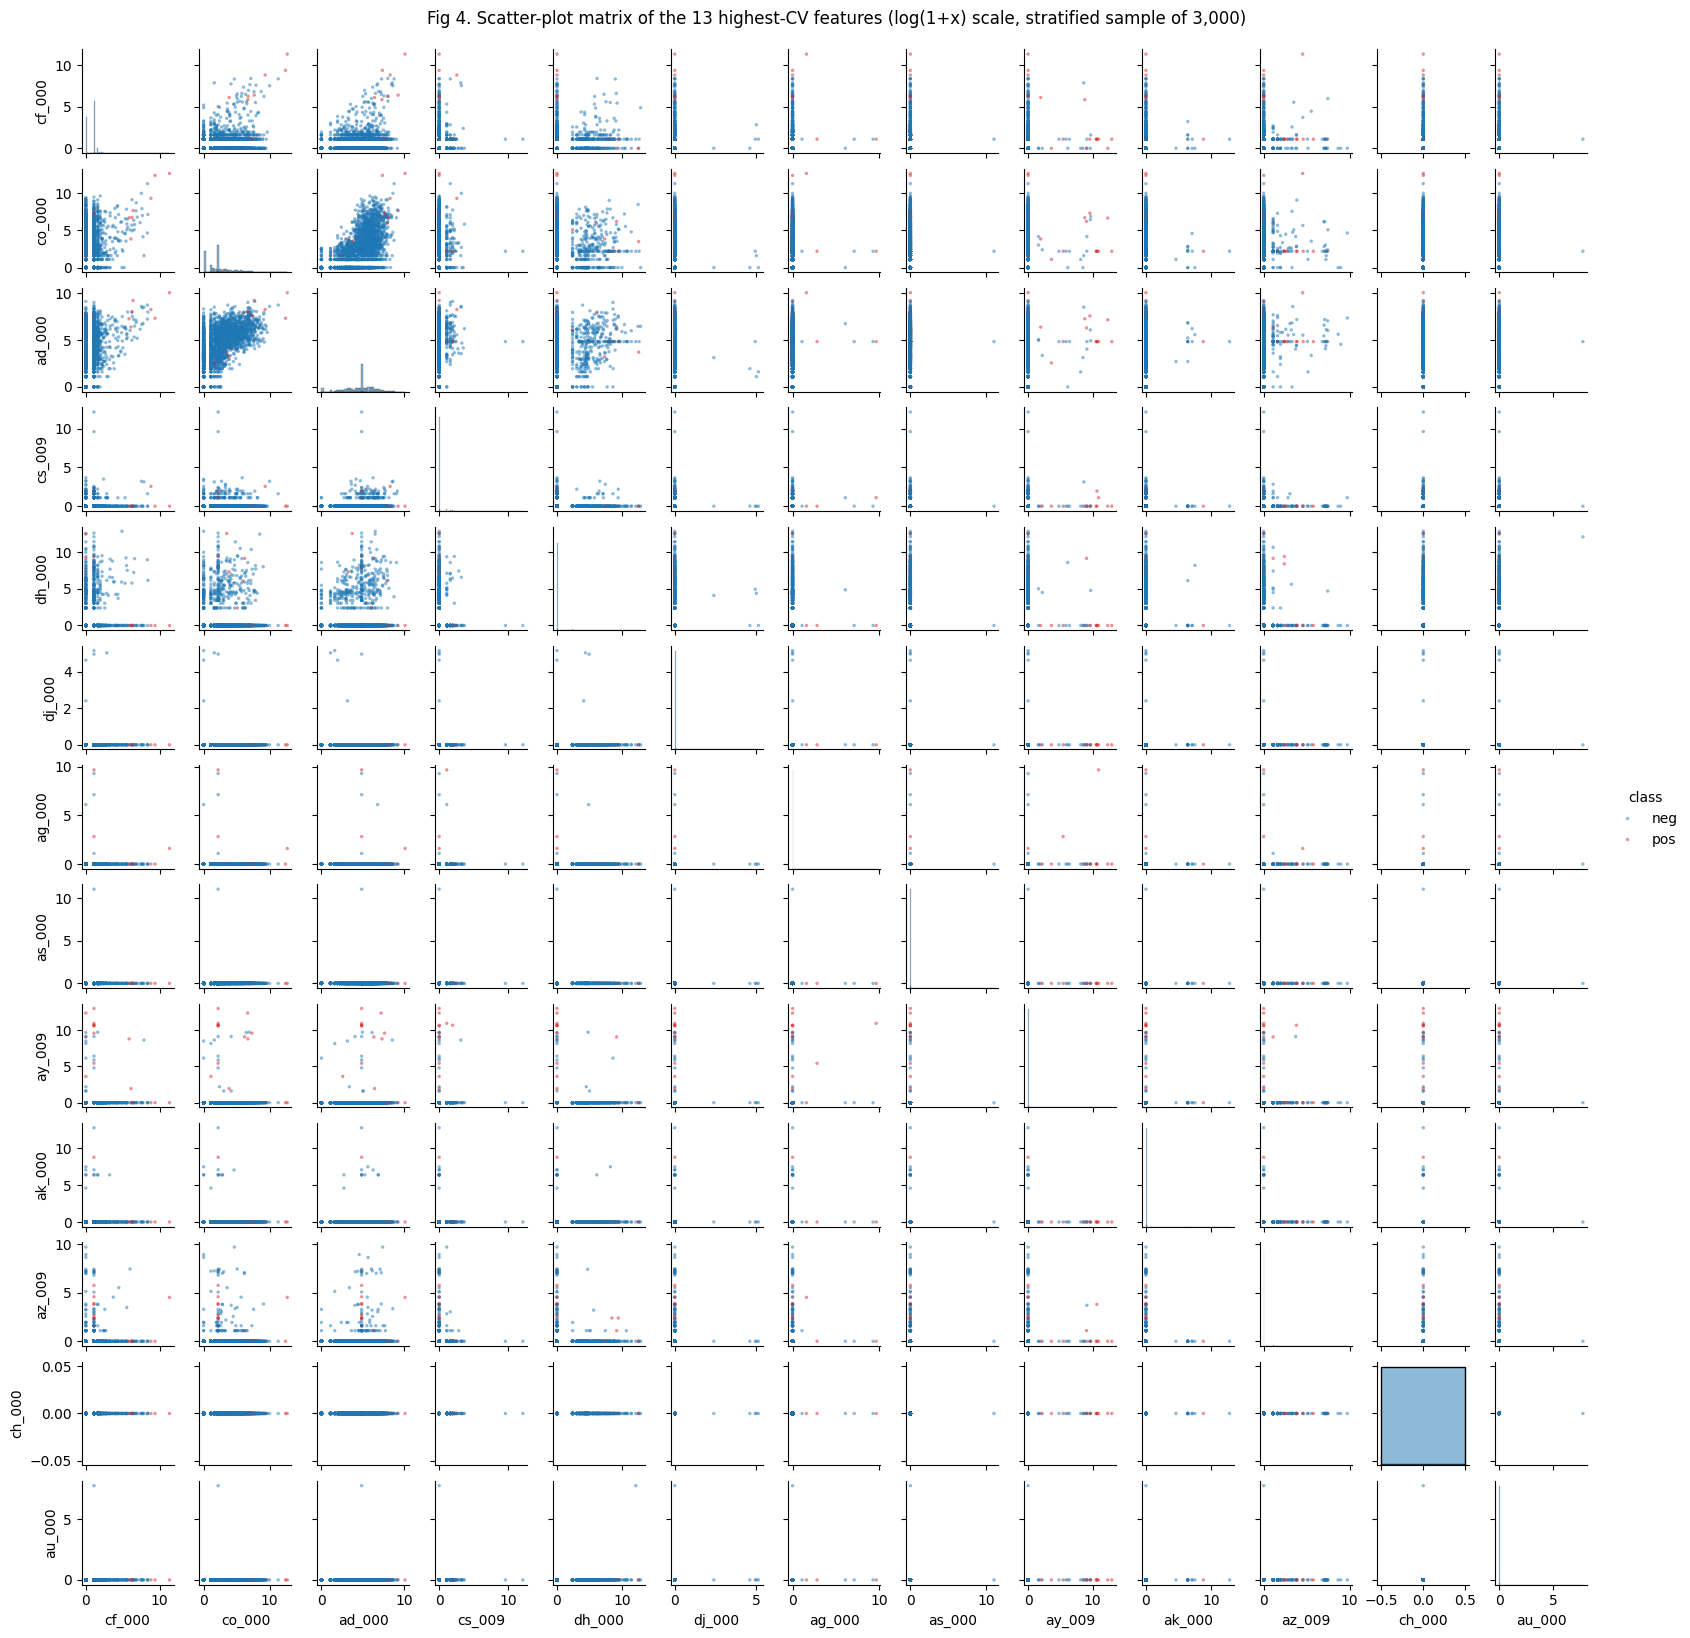

In [8]:
k = int(np.floor(np.sqrt(170)))
top_cv = cv_df.index[:k].tolist()
print(f"k = {k}; top-CV features: {top_cv}")

plot_df = X_train[top_cv].copy()
plot_df["class"] = np.where(y_train == 1, "pos", "neg")
from sklearn.model_selection import train_test_split
sample, _ = train_test_split(plot_df, train_size=3000, stratify=plot_df["class"], random_state=SEED)

sample_log = sample.copy()
sample_log[top_cv] = np.log1p(sample_log[top_cv])   # features span many orders of magnitude
g = sns.pairplot(sample_log, vars=top_cv, hue="class", hue_order=["neg", "pos"],
                 palette={"neg": "tab:blue", "pos": "tab:red"},
                 plot_kws={"s": 6, "alpha": 0.5, "linewidth": 0}, diag_kind="hist",
                 height=1.25, corner=False)
g.fig.suptitle("Fig 4. Scatter-plot matrix of the 13 highest-CV features (log(1+x) scale, stratified sample of 3,000)", y=1.01)
plt.show()

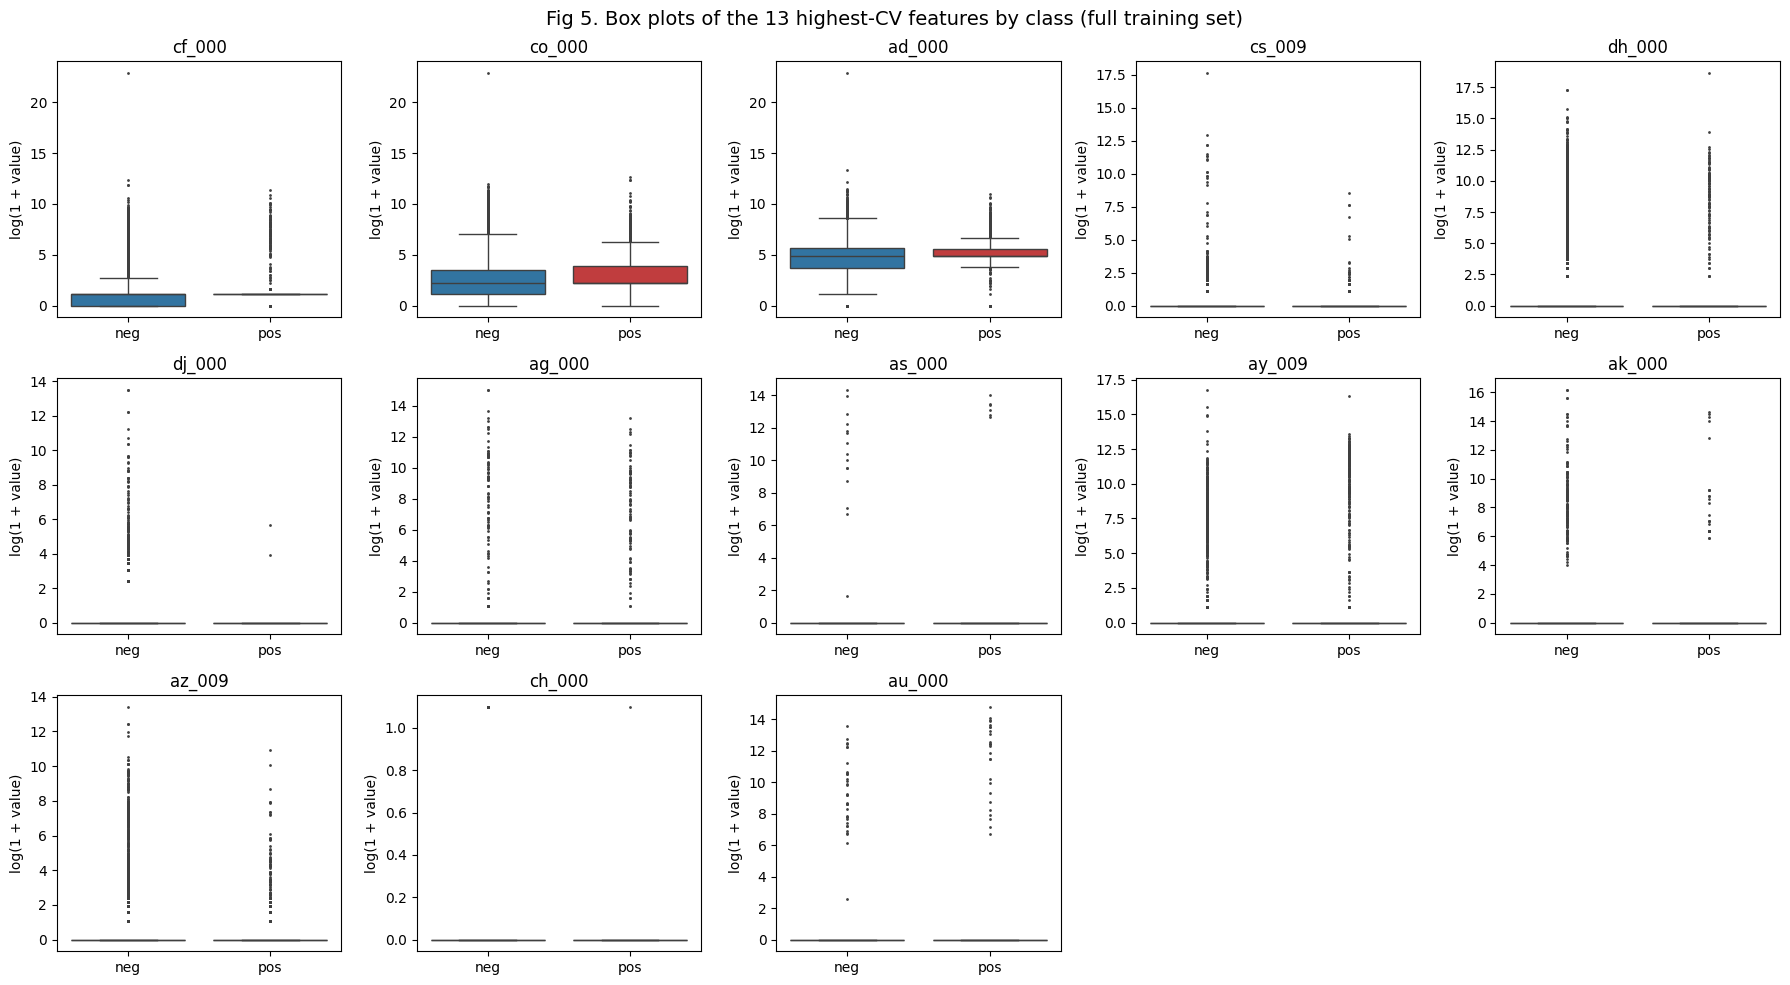

In [9]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, f in zip(axes.ravel(), top_cv):
    sns.boxplot(x=plot_df["class"], y=np.log1p(plot_df[f]), order=["neg", "pos"],
                palette={"neg": "tab:blue", "pos": "tab:red"}, ax=ax, fliersize=1)
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("log(1 + value)")
for ax in axes.ravel()[k:]:
    ax.axis("off")
fig.suptitle("Fig 5. Box plots of the 13 highest-CV features by class (full training set)", fontsize=14)
plt.tight_layout(); plt.show()

**Can we draw conclusions about the significance of these features from the scatter plots alone?**

Not reliably. (Note: `ch_000` is 0 for almost every row after median imputation, so its panels are degenerate.) In the scatter-plot matrix the positive (red) points do tend to sit at larger values for several features (the box plots show the same thing: the median of the `pos` class is clearly higher for most of them). That suggests these features carry *some* information about the class. But scatter plots only show marginal and pairwise relationships, the classes overlap heavily, and positives are only 1.67 % of the points, so they are easy to miss or over-read. A high CV only means a feature is spread out, not that it is predictive. To decide whether a feature is significant we need a formal test or a model (e.g., p-values from a regression, or feature importances / cross-validated performance). The plots are only a rough first look.

#### (b) v. Number of positive and negative data

In [10]:
for name, y in [("Train", y_train), ("Test", y_test)]:
    print(f"{name}: positive = {y.sum():5d}, negative = {(1 - y).sum():5d}, positive rate = {y.mean():.4f}")

Train: positive =  1000, negative = 59000, positive rate = 0.0167
Test: positive =   375, negative = 15625, positive rate = 0.0234


**Yes, the data set is severely imbalanced.** The training set has 1,000 positives and 59,000 negatives (about 1 : 59). A classifier that always predicts "neg" already gets about 98.3 % accuracy, so accuracy alone is a misleading metric here. We also report confusion matrices, ROC and AUC.

### Helper functions for evaluation

In [11]:
results = {}   # collect summary metrics for the final comparison

def evaluate(name, model, X_tr, y_tr, X_te, y_te, p_tr=None, p_te=None):
    # Report confusion matrix, ROC, AUC and misclassification for train and test sets
    if p_tr is None: p_tr = model.predict_proba(X_tr)[:, 1]
    if p_te is None: p_te = model.predict_proba(X_te)[:, 1]
    yhat_tr, yhat_te = (p_tr >= 0.5).astype(int), (p_te >= 0.5).astype(int)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    summary = {}
    for ax, split, y, yhat in [(axes[0], "Train", y_tr, yhat_tr), (axes[1], "Test", y_te, yhat_te)]:
        cm = confusion_matrix(y, yhat, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["neg", "pos"]).plot(ax=ax, colorbar=False, values_format="d")
        ax.set_title(f"{name}\nConfusion matrix ({split})")
        tn, fp, fn, tp = cm.ravel()
        summary[split] = dict(TN=tn, FP=fp, FN=fn, TP=tp,
                              misclassification=1 - accuracy_score(y, yhat),
                              AUC=roc_auc_score(y, p_tr if split == "Train" else p_te))
    for split, y, p, c in [("Train", y_tr, p_tr, "tab:green"), ("Test", y_te, p_te, "tab:purple")]:
        fpr, tpr, _ = roc_curve(y, p)
        axes[2].plot(fpr, tpr, color=c, label=f"{split} (AUC = {summary[split]['AUC']:.4f})")
    axes[2].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
    axes[2].set_title(f"{name}\nROC curves"); axes[2].legend(loc="lower right")
    plt.tight_layout(); plt.show()

    df = pd.DataFrame(summary).T[["TN", "FP", "FN", "TP", "misclassification", "AUC"]]
    df["misclassification"] = df["misclassification"].astype(float).round(5)
    df["AUC"] = df["AUC"].astype(float).round(5)
    display(df)
    results[name] = summary
    return summary

### (c) Random forest without compensating for class imbalance

Training time: 15.6 s


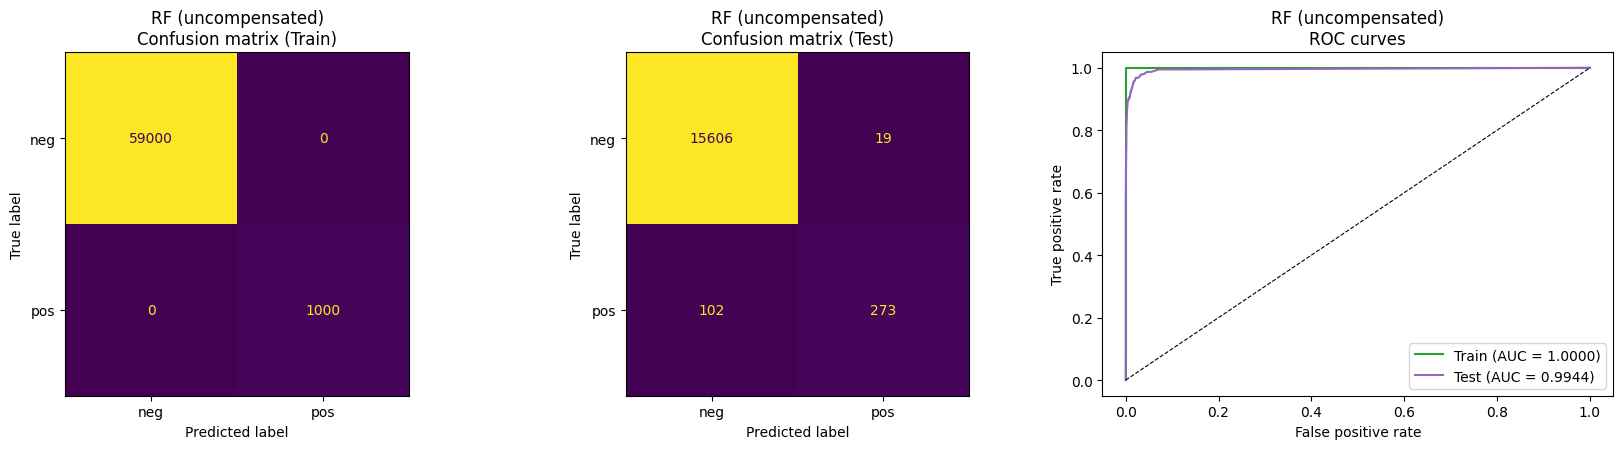

,TN,FP,FN,TP,misclassification,AUC
Train,59000.0,0.0,0.0,1000.0,0.00000,1.00000
Test,15606.0,19.0,102.0,273.0,0.00756,0.99438


In [12]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, max_features="sqrt", oob_score=True,
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
print(f"Training time: {time.time() - t0:.1f} s")

rf_summary = evaluate("RF (uncompensated)", rf, X_train, y_train, X_test, y_test)

In [13]:
rf_oob_err = 1 - rf.oob_score_
rf_test_err = rf_summary["Test"]["misclassification"]
print(f"OOB error estimate : {rf_oob_err:.5f}")
print(f"Test error         : {rf_test_err:.5f}")
print(f"Training error     : {rf_summary['Train']['misclassification']:.5f}")

OOB error estimate : 0.00580
Test error         : 0.00756
Training error     : 0.00000


**Results and OOB vs. test error (1c).** See the tables above. The forest fits the training set almost perfectly (training error ≈ 0, AUC = 1), which is expected for fully grown trees and says nothing about generalization. The OOB error is close to the test error, so it is a good, nearly free estimate of the test error. The test confusion matrix shows the real issue: almost all errors are **false negatives**, i.e., actual APS failures predicted as `neg`. The model gets high accuracy mostly by predicting the majority class, and its recall on the positive class is much lower than its overall accuracy suggests. (The AUC stays high because the predicted probabilities still *rank* positives well; the 0.5 threshold is just too high for such a rare class.)

### (d) Compensating for class imbalance in random forests

Common ways to address class imbalance in random forests (Chen, Liaw & Breiman, 2004, *Using Random Forest to Learn Imbalanced Data*):

1. **Weighted random forest (cost-sensitive learning)**: give the minority class a larger weight. Weights enter the Gini impurity when choosing splits and the weighted vote in the terminal nodes (`class_weight="balanced"` / `"balanced_subsample"` in scikit-learn).
2. **Balanced random forest (sampling)**: for every tree, draw a bootstrap sample from the minority class and draw *the same number* of cases (with replacement) from the majority class, so each tree is trained on balanced data (`BalancedRandomForestClassifier` in imbalanced-learn).
3. **Resampling the training data before fitting**: random oversampling of the minority class, undersampling of the majority class, or synthetic oversampling (SMOTE).
4. **Moving the decision threshold** (predict `pos` when the vote share for `pos` is greater than some threshold below 0.5).

Below we use the **balanced random forest** (method 2). With fully grown trees, class weights alone (method 1) change the results only a little, because the leaves are pure anyway. Balanced bootstrap sampling changes what every tree sees. For reference, a weighted forest is also fit and its test metrics are printed.

Training time: 0.9 s


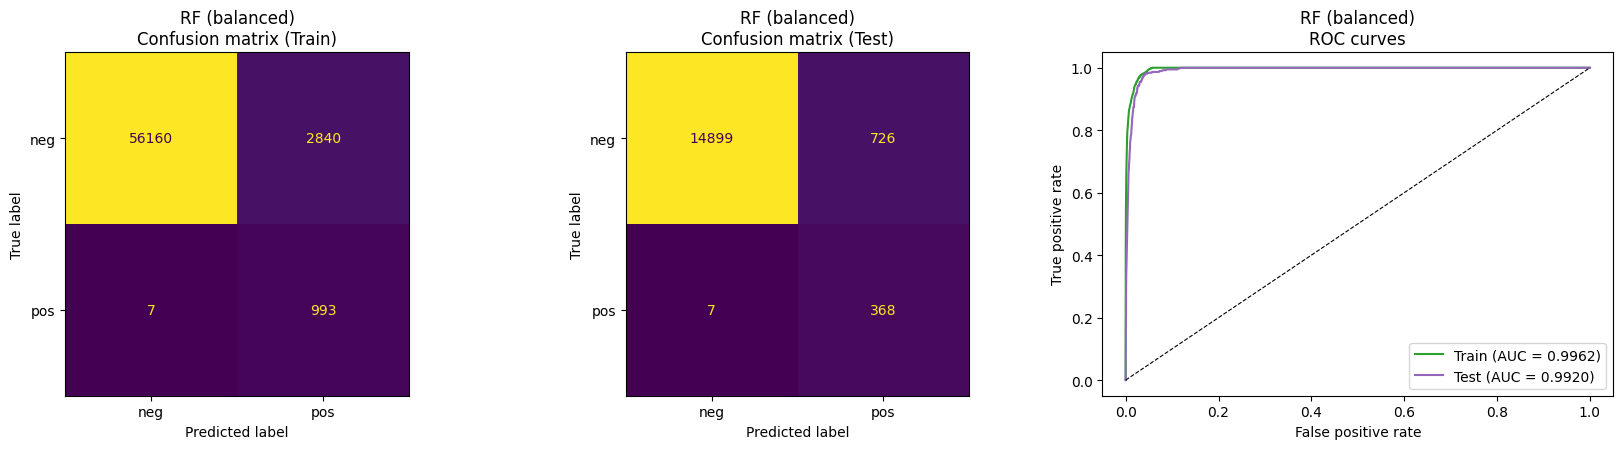

,TN,FP,FN,TP,misclassification,AUC
Train,56160.0,2840.0,7.0,993.0,0.04745,0.99617
Test,14899.0,726.0,7.0,368.0,0.04581,0.99197


In [14]:
t0 = time.time()
brf = BalancedRandomForestClassifier(n_estimators=200, max_features="sqrt", sampling_strategy="all",
                                     replacement=True, bootstrap=True, oob_score=True,
                                     n_jobs=-1, random_state=SEED)
brf.fit(X_train, y_train)
print(f"Training time: {time.time() - t0:.1f} s")

brf_summary = evaluate("RF (balanced)", brf, X_train, y_train, X_test, y_test)

In [15]:
brf_oob_err = 1 - brf.oob_score_
print(f"Balanced RF - OOB error estimate : {brf_oob_err:.5f}")
print(f"Balanced RF - Test error         : {brf_summary['Test']['misclassification']:.5f}")

# Reference: weighted random forest (cost-sensitive), test set only
wrf = RandomForestClassifier(n_estimators=200, max_features="sqrt", class_weight="balanced_subsample",
                             n_jobs=-1, random_state=SEED).fit(X_train, y_train)
p = wrf.predict_proba(X_test)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_test, (p >= 0.5).astype(int)).ravel()
print(f"\nWeighted RF (reference) - test: TN={tn} FP={fp} FN={fn} TP={tp}, "
      f"misclassification={(fp + fn) / len(y_test):.5f}, AUC={roc_auc_score(y_test, p):.5f}")

Balanced RF - OOB error estimate : 0.03938
Balanced RF - Test error         : 0.04581

Weighted RF (reference) - test: TN=15608 FP=17 FN=154 TP=221, misclassification=0.01069, AUC=0.99330


In [16]:
def comparison_table(names):
    rows = []
    for n in names:
        s = results[n]["Test"]
        rows.append(dict(model=n, TP=s["TP"], FN=s["FN"], FP=s["FP"], TN=s["TN"],
                         recall_pos=s["TP"] / (s["TP"] + s["FN"]),
                         precision_pos=s["TP"] / (s["TP"] + s["FP"]),
                         misclassification=s["misclassification"], AUC=s["AUC"]))
    return pd.DataFrame(rows).set_index("model").round(4)

comparison_table(["RF (uncompensated)", "RF (balanced)"])

,TP,FN,FP,TN,recall_pos,precision_pos,misclassification,AUC
model,,,,,,,,
RF (uncompensated),273,102,19,15606,0.7280,0.9349,0.0076,0.9944
RF (balanced),368,7,726,14899,0.9813,0.3364,0.0458,0.9920


**Comparison with 1c.** The balanced forest trades overall accuracy for much better detection of the rare class. Recall on the positive class goes up a lot (far fewer missed APS failures, FN), at the cost of many more false positives (FP), so the plain misclassification rate goes **up**. The test AUC is about the same (0.992 vs. 0.994), since both forests rank the cases well; the balanced forest effectively moves the operating point along the ROC curve toward higher sensitivity. Because the training error is no longer ≈ 0, the OOB error and the test error are again close to each other.

For this problem a missed failure (FN) is much more expensive than an unnecessary check (FP). The Scania data description assigns cost 500 to an FN and cost 10 to an FP. So the compensated model is the more useful one, even though its accuracy is lower.

In [17]:
def scania_cost(name):
    s = results[name]["Test"]
    return 10 * s["FP"] + 500 * s["FN"]
for n in ["RF (uncompensated)", "RF (balanced)"]:
    print(f"{n:22s}: Scania test cost = 10*FP + 500*FN = {scania_cost(n)}")

RF (uncompensated)    : Scania test cost = 10*FP + 500*FN = 51190
RF (balanced)         : Scania test cost = 10*FP + 500*FN = 10760


### (e) XGBoost and model trees (L1-penalized, logistic loss), no compensation for class imbalance

We fit XGBoost with the `binary:logistic` objective, i.e., the model is fit by minimizing the logistic-regression loss, with an **L1 penalty** on the leaf weights (`reg_alpha` = α). α is chosen by **5-fold stratified cross-validation** over a grid. The CV error of the chosen model is then compared with the test error.

*Note on CV metric:* α is selected by cross-validated AUC, which is not affected by the 0.5 threshold and is more informative than accuracy on such imbalanced data. The CV **misclassification error** is reported as the error estimate.

In [18]:
XGB_PARAMS = dict(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=1.0,
                  objective="binary:logistic", tree_method="hist", eval_metric="logloss",
                  n_jobs=-1, random_state=SEED)
ALPHAS = [0, 0.01, 0.1, 1, 10, 100]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_alpha(make_model, X, y):
    rows, oof = [], {}
    for a in ALPHAS:
        t0 = time.time()
        p = cross_val_predict(make_model(a), X, y, cv=skf, method="predict_proba")[:, 1]
        oof[a] = p
        rows.append(dict(alpha=a, cv_AUC=roc_auc_score(y, p),
                         cv_error=np.mean((p >= 0.5).astype(int) != y), seconds=time.time() - t0))
    return pd.DataFrame(rows).set_index("alpha"), oof

cv_xgb, oof_xgb = cv_alpha(lambda a: XGBClassifier(reg_alpha=a, **XGB_PARAMS), X_train, y_train)
cv_xgb.round(5)

,cv_AUC,cv_error,seconds
alpha,,,
0.00,0.98848,0.00567,7.39659
0.01,0.98882,0.00565,7.26292
0.10,0.98851,0.00563,7.33670
1.00,0.98855,0.00582,8.13343
10.00,0.98830,0.00710,5.93535
100.00,0.98219,0.01128,4.37591


Selected alpha (max 5-fold CV AUC): 0.01


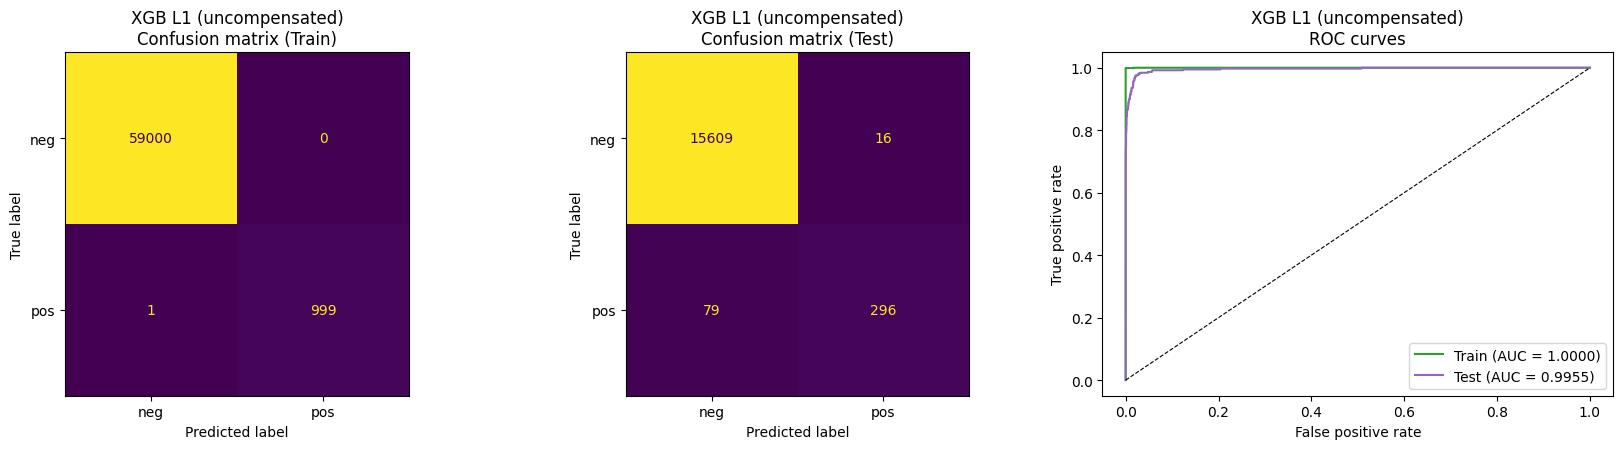

,TN,FP,FN,TP,misclassification,AUC
Train,59000.0,0.0,1.0,999.0,0.00002,0.99998
Test,15609.0,16.0,79.0,296.0,0.00594,0.99555


5-fold CV error estimate : 0.00565
Test error               : 0.00594
5-fold CV AUC            : 0.98882


In [19]:
best_alpha = cv_xgb["cv_AUC"].idxmax()
print(f"Selected alpha (max 5-fold CV AUC): {best_alpha}")

xgb = XGBClassifier(reg_alpha=best_alpha, **XGB_PARAMS).fit(X_train, y_train)
xgb_summary = evaluate("XGB L1 (uncompensated)", xgb, X_train, y_train, X_test, y_test)

xgb_cv_err = cv_xgb.loc[best_alpha, "cv_error"]
print(f"5-fold CV error estimate : {xgb_cv_err:.5f}")
print(f"Test error               : {xgb_summary['Test']['misclassification']:.5f}")
print(f"5-fold CV AUC            : {cv_xgb.loc[best_alpha, 'cv_AUC']:.5f}")

**CV error vs. test error (1e).** The 5-fold CV error is close to the test error, so cross-validation gives a good estimate of how the model generalizes. Like the uncompensated forest, the boosted model has near-zero training error and high accuracy. Most of its test errors are again false negatives, since nothing pushes it toward the rare class.

### (f) SMOTE + XGBoost (L1-penalized logistic loss)

**Right vs. wrong way to cross-validate with SMOTE.** The *wrong* way is to apply SMOTE to the whole training set and then cross-validate on it. The synthetic positives are interpolations of real positives, so the validation folds would contain points that are near-copies of points in the training folds. This leaks information and gives an overly optimistic CV estimate. The validation folds would also have an artificial 50/50 class balance instead of the real ~1.7 % positive rate.

The *right* way is to put SMOTE **inside** the CV loop: in each fold, SMOTE is fit and applied **only to the training part** of that fold, and the model is evaluated on the untouched, original-distribution validation part. `imblearn.pipeline.Pipeline` does exactly this. After α is chosen, SMOTE is applied to the **full** training set (59,000 neg + 59,000 synthetic-augmented pos = 118,000 rows), the final model is trained on it, and it is evaluated on the original test set.

In [20]:
make_smote_xgb = lambda a: ImbPipeline([("smote", SMOTE(k_neighbors=5, random_state=SEED)),
                                        ("xgb", XGBClassifier(reg_alpha=a, **XGB_PARAMS))])
cv_smote, oof_smote = cv_alpha(make_smote_xgb, X_train, y_train)   # SMOTE applied inside each training fold only
cv_smote.round(5)

,cv_AUC,cv_error,seconds
alpha,,,
0.00,0.98795,0.00688,16.17522
0.01,0.98834,0.00690,16.35494
0.10,0.98880,0.00677,16.92793
1.00,0.98775,0.00710,19.86474
10.00,0.98742,0.00795,19.37125
100.00,0.98442,0.01785,18.22080


Selected alpha with SMOTE (max 5-fold CV AUC): 0.1
SMOTE on full training set: 118000 rows, positives = 59000, negatives = 59000 (0.5 s)


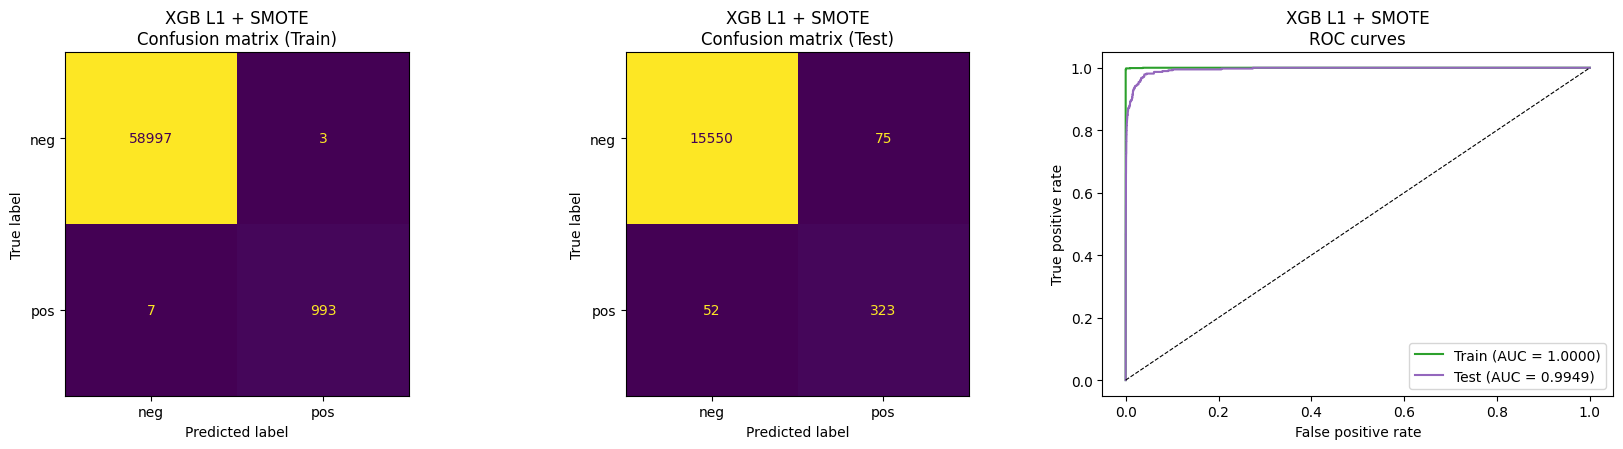

,TN,FP,FN,TP,misclassification,AUC
Train,58997.0,3.0,7.0,993.0,0.00017,0.99995
Test,15550.0,75.0,52.0,323.0,0.00794,0.99487


5-fold CV error estimate (SMOTE inside folds) : 0.00677
Test error                                    : 0.00794
5-fold CV AUC                                 : 0.98880


In [21]:
best_alpha_s = cv_smote["cv_AUC"].idxmax()
print(f"Selected alpha with SMOTE (max 5-fold CV AUC): {best_alpha_s}")

t0 = time.time()
X_sm, y_sm = SMOTE(k_neighbors=5, random_state=SEED).fit_resample(X_train, y_train)   # full training set
print(f"SMOTE on full training set: {X_sm.shape[0]} rows, positives = {y_sm.sum()}, negatives = {(1 - y_sm).sum()} "
      f"({time.time() - t0:.1f} s)")

xgb_sm = XGBClassifier(reg_alpha=best_alpha_s, **XGB_PARAMS).fit(X_sm, y_sm)
# Training-set metrics are reported on the original (non-synthetic) training data
smote_summary = evaluate("XGB L1 + SMOTE", xgb_sm, X_train, y_train, X_test, y_test)

smote_cv_err = cv_smote.loc[best_alpha_s, "cv_error"]
print(f"5-fold CV error estimate (SMOTE inside folds) : {smote_cv_err:.5f}")
print(f"Test error                                    : {smote_summary['Test']['misclassification']:.5f}")
print(f"5-fold CV AUC                                 : {cv_smote.loc[best_alpha_s, 'cv_AUC']:.5f}")

In [22]:
# For illustration only: the WRONG way (SMOTE the whole training set first, then cross-validate)
p_wrong = cross_val_predict(XGBClassifier(reg_alpha=best_alpha_s, **XGB_PARAMS), X_sm, y_sm,
                            cv=skf, method="predict_proba")[:, 1]
print(f"WRONG-way CV error: {np.mean((p_wrong >= 0.5) != y_sm):.5f} | WRONG-way CV AUC: {roc_auc_score(y_sm, p_wrong):.5f}")
print("-> optimistic, and measured on an artificial 50/50 distribution, so it does not reflect the real test error.")

WRONG-way CV error: 0.00263 | WRONG-way CV AUC: 0.99995
-> optimistic, and measured on an artificial 50/50 distribution, so it does not reflect the real test error.


In [23]:
cmp = comparison_table(["RF (uncompensated)", "RF (balanced)", "XGB L1 (uncompensated)", "XGB L1 + SMOTE"])
cmp["Scania cost (10FP+500FN)"] = [scania_cost(n) for n in cmp.index]
cmp["error estimate"] = [rf_oob_err, brf_oob_err, xgb_cv_err, smote_cv_err]
cmp["estimate type"] = ["OOB", "OOB", "5-fold CV", "5-fold CV (SMOTE in folds)"]
cmp

,TP,FN,FP,TN,recall_pos,precision_pos,misclassification,AUC,Scania cost (10FP+500FN),error estimate,estimate type
model,,,,,,,,,,,
RF (uncompensated),273,102,19,15606,0.7280,0.9349,0.0076,0.9944,51190,0.005800,OOB
RF (balanced),368,7,726,14899,0.9813,0.3364,0.0458,0.9920,10760,0.039383,OOB
XGB L1 (uncompensated),296,79,16,15609,0.7893,0.9487,0.0059,0.9955,39660,0.005650,5-fold CV
XGB L1 + SMOTE,323,52,75,15550,0.8613,0.8116,0.0079,0.9949,26750,0.006767,5-fold CV (SMOTE in folds)


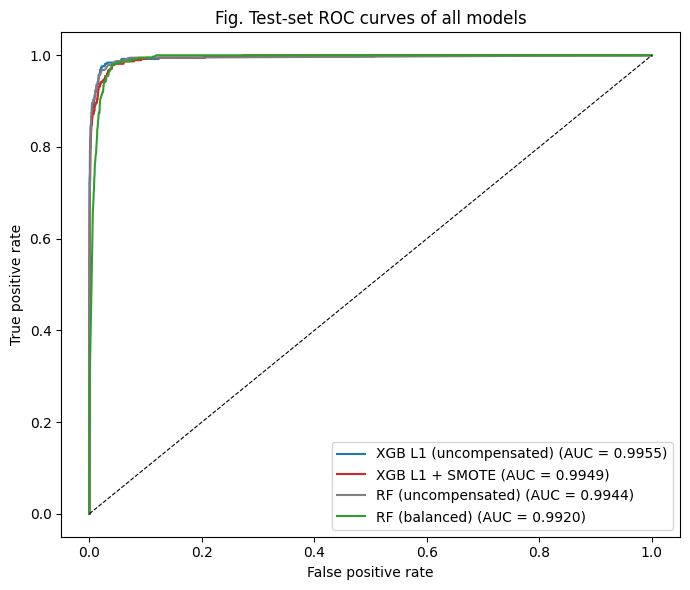

In [24]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, model, c in [("XGB L1 (uncompensated)", xgb, "tab:blue"), ("XGB L1 + SMOTE", xgb_sm, "tab:red"),
                       ("RF (uncompensated)", rf, "tab:gray"), ("RF (balanced)", brf, "tab:green")]:
    p = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=c, label=f"{name} (AUC = {roc_auc_score(y_test, p):.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Fig. Test-set ROC curves of all models"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Comparison: uncompensated XGBoost (1e) vs. SMOTE + XGBoost (1f)** (numbers from the table above)

| Test set | XGB L1, uncompensated | XGB L1 + SMOTE |
|---|---|---|
| Selected α (5-fold CV) | 0.01 | 0.1 |
| TP / FN | 296 / 79 | 323 / 52 |
| FP | 16 | 75 |
| Recall (pos) | 0.789 | 0.861 |
| Precision (pos) | 0.949 | 0.812 |
| Misclassification | 0.0059 | 0.0079 |
| AUC | 0.9955 | 0.9949 |
| CV error estimate | 0.0057 | 0.0068 (SMOTE inside folds) |
| Scania cost 10·FP + 500·FN | 39,660 | 26,750 |

- **Effect of SMOTE.** Training on SMOTE-balanced data moves the classifier toward the minority class. It catches 27 more failures (FN 79 → 52, recall 0.79 → 0.86) at the price of 59 more false alarms (FP 16 → 75). The overall misclassification rate rises slightly (0.59 % → 0.79 %), because negatives dominate the test set. AUC is essentially unchanged (≈ 0.995 for both), which shows that SMOTE mainly shifts the operating point on the ROC curve rather than improving the model's ranking ability.
- **CV vs. test error.** In both cases the 5-fold CV error is close to the test error (0.0057 vs. 0.0059, and 0.0068 vs. 0.0079), so the CV estimates are reliable. That is only true because SMOTE was applied **inside** each training fold. The wrong way (SMOTE first, then CV) gives an error of 0.0026 and AUC ≈ 1.0 on an artificial 50/50 distribution, which is far too optimistic.
- **Which is better?** By accuracy, the uncompensated model is slightly better. With the Scania costs (a missed failure costs 50 times a false alarm), SMOTE reduces the total cost by about a third (39,660 → 26,750). The balanced random forest of 1d is even more aggressive (FN = 7, cost 10,820). So when missing a failure is expensive, compensating for class imbalance is clearly worth it, even though plain accuracy goes down.


## 2. ISLR 6.6.3

We estimate the coefficients by minimizing $\sum_{i=1}^n\big(y_i-\beta_0-\sum_{j=1}^p\beta_jx_{ij}\big)^2$ subject to $\sum_{j=1}^p|\beta_j|\le s$, as $s$ increases from 0.

At $s=0$ all $\beta_j=0$ (the null model, most restrictive). As $s$ grows the constraint loosens, the model becomes more flexible, and for large enough $s$ we get the least-squares solution.

**(a) Training RSS: (iv) steadily decreases.** A larger $s$ enlarges the feasible set, so the minimum training RSS can only go down (or stay the same once $s$ reaches the least-squares solution).

**(b) Test RSS: (ii) decreases initially, and then eventually starts increasing in a U shape.** At first, adding flexibility removes a lot of bias, so test RSS falls. Past some point the model starts fitting noise (variance grows faster than bias falls), and test RSS rises.

**(c) Variance: (iii) steadily increases.** At $s=0$ the model is a constant and has (almost) no variance. As $s$ grows, the coefficients depend more and more on the particular training sample, so variance increases.

**(d) Squared bias: (iv) steadily decreases.** A more flexible model can approximate the true $f$ more closely, so squared bias goes down.

**(e) Irreducible error: (v) remains constant.** $\mathrm{Var}(\epsilon)$ does not depend on the model, so it does not change with $s$.

## 3. ISLR 6.6.5

Setting: $n=2,\ p=2$, $x_{11}=x_{12}$, $x_{21}=x_{22}$, $y_1+y_2=0$, $x_{11}+x_{21}=0$, $x_{12}+x_{22}=0$, so the least-squares, ridge and lasso intercepts are all $\hat\beta_0=0$. Write $x_1 := x_{11}=x_{12}$ and $x_2 := x_{21}=x_{22}$. Then $x_2=-x_1$ and $y_2=-y_1$.

**(a) Ridge optimization problem**

$$\min_{\beta_1,\beta_2}\ (y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(\beta_1^2+\beta_2^2)$$

**(b) Show that the ridge estimates satisfy $\hat\beta_1=\hat\beta_2$.**

With the setting above, the objective is
$$f(\beta_1,\beta_2)=(y_1-(\beta_1+\beta_2)x_1)^2+(y_2-(\beta_1+\beta_2)x_2)^2+\lambda(\beta_1^2+\beta_2^2).$$
Using $x_2=-x_1$ and $y_2=-y_1$, the two squared terms are equal, so
$$f=2\big(y_1-(\beta_1+\beta_2)x_1\big)^2+\lambda(\beta_1^2+\beta_2^2).$$
Set the partial derivatives to zero:
$$\frac{\partial f}{\partial\beta_1}=-4x_1\big(y_1-(\beta_1+\beta_2)x_1\big)+2\lambda\beta_1=0,\qquad
\frac{\partial f}{\partial\beta_2}=-4x_1\big(y_1-(\beta_1+\beta_2)x_1\big)+2\lambda\beta_2=0.$$
Subtracting the two equations gives $2\lambda(\beta_1-\beta_2)=0$, so for $\lambda>0$, $\hat\beta_1=\hat\beta_2$. (The objective is strictly convex for $\lambda>0$, so this stationary point is the unique minimizer.) Solving, $\hat\beta_1=\hat\beta_2=\dfrac{2x_1y_1}{4x_1^2+\lambda}$.

**(c) Lasso optimization problem**

$$\min_{\beta_1,\beta_2}\ (y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(|\beta_1|+|\beta_2|)$$

**(d) The lasso coefficients are not unique.**

As before, the objective becomes
$$g(\beta_1,\beta_2)=2\big(y_1-(\beta_1+\beta_2)x_1\big)^2+\lambda(|\beta_1|+|\beta_2|).$$
The RSS part depends only on the sum $b=\beta_1+\beta_2$. For a fixed $b$, the penalty $|\beta_1|+|\beta_2|\ge|\beta_1+\beta_2|=|b|$, with equality **whenever $\beta_1$ and $\beta_2$ have the same sign** (or one is zero). So minimizing $g$ is the same as minimizing $2(y_1-bx_1)^2+\lambda|b|$ over $b$, which gives one optimal value $\hat b$. Then **every** pair with $\beta_1+\beta_2=\hat b$ and $\beta_1\beta_2\ge0$ is a solution:
$$\{(\beta_1,\beta_2):\ \beta_1+\beta_2=\hat b,\ \beta_1\ge0,\ \beta_2\ge0\}\ \text{(if }\hat b>0\text{)},\quad\text{or}\quad\{\beta_1+\beta_2=\hat b,\ \beta_1\le0,\ \beta_2\le0\}\ \text{(if }\hat b<0\text{)}.$$
Geometrically, the RSS contours are lines parallel to $\beta_1+\beta_2=\text{const}$. The lasso diamond $|\beta_1|+|\beta_2|\le s$ has an edge on exactly such a line, so the contour touches the constraint region along a whole edge, not at a single point. Here $\hat b=\operatorname{sign}(x_1y_1)\,\max\!\big(0,\ \tfrac{4|x_1y_1|-\lambda}{4x_1^2}\big)$.

## 4. ISLR 8.4.5

Ten bootstrap estimates of $P(\text{Class is Red}\mid X)$: 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.

In [25]:
probs = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
votes_red = (probs > 0.5).sum()
print(f"Majority vote: {votes_red} Red vs {len(probs) - votes_red} Green -> {'Red' if votes_red > len(probs) / 2 else 'Green'}")
print(f"Average probability: {probs.mean():.2f} -> {'Red' if probs.mean() > 0.5 else 'Green'}")

Majority vote: 6 Red vs 4 Green -> Red
Average probability: 0.45 -> Green


- **Majority vote:** 6 of the 10 estimates are above 0.5, so 6 trees vote Red and 4 vote Green. The final classification is **Red**.
- **Average probability:** the mean is $4.5/10 = 0.45 < 0.5$, so the final classification is **Green**.

The two combining rules can disagree. The average is pulled down by the four very confident Green estimates (0.1–0.2), while the six Red estimates are only mildly above 0.5.

## 5. ISLR 9.7.3

| Obs. | $X_1$ | $X_2$ | $Y$ |
|---|---|---|---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

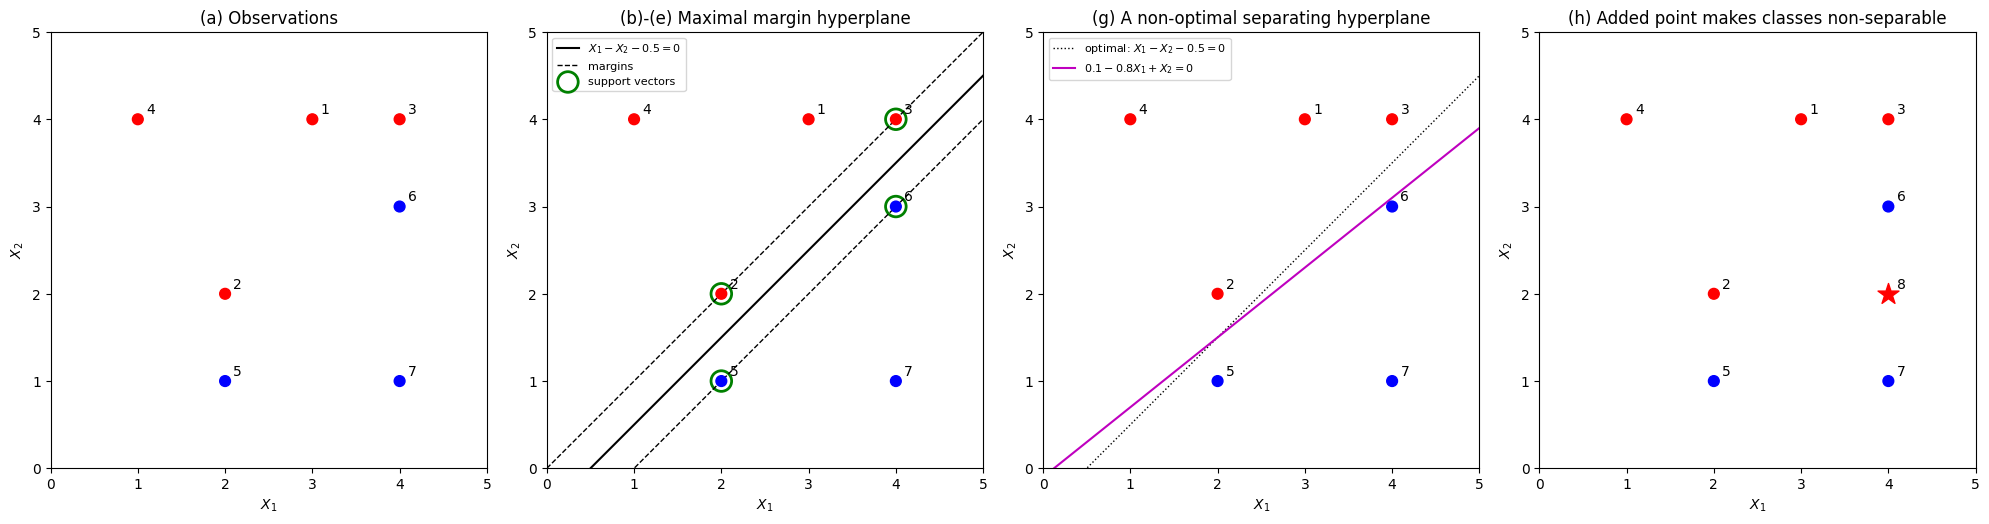

f(x) = 0.5 - X1 + X2 on Red : [1.5 0.5 0.5 3.5]  (all > 0)
f(x) = 0.5 - X1 + X2 on Blue: [-0.5 -0.5 -2.5]  (all < 0)
Margin = 0.5 / sqrt(2) = 0.3536
(g) 0.1 - 0.8X1 + X2 on Red: [1.7 0.5 0.9 3.3] | on Blue: [-0.5 -0.1 -2.1]


In [26]:
pts = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
cols = np.array(["red"] * 4 + ["blue"] * 3)
xs = np.linspace(0, 5, 100)

def base(ax, title):
    ax.scatter(pts[:, 0], pts[:, 1], c=cols, s=60, zorder=3)
    for i, (a, b) in enumerate(pts, 1):
        ax.annotate(str(i), (a, b), textcoords="offset points", xytext=(6, 4))
    ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_aspect("equal")
    ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_title(title)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
base(axes[0], "(a) Observations")

base(axes[1], "(b)-(e) Maximal margin hyperplane")
axes[1].plot(xs, xs - 0.5, "k-", label="$X_1 - X_2 - 0.5 = 0$")
axes[1].plot(xs, xs, "k--", lw=1, label="margins")
axes[1].plot(xs, xs - 1, "k--", lw=1)
sv = pts[[1, 2, 4, 5]]
axes[1].scatter(sv[:, 0], sv[:, 1], s=220, facecolors="none", edgecolors="green", linewidths=2, label="support vectors")
axes[1].legend(loc="upper left", fontsize=8)

base(axes[2], "(g) A non-optimal separating hyperplane")
axes[2].plot(xs, xs - 0.5, "k:", lw=1, label="optimal: $X_1 - X_2 - 0.5 = 0$")
axes[2].plot(xs, 0.8 * xs - 0.1, "m-", label="$0.1 - 0.8X_1 + X_2 = 0$")
axes[2].legend(loc="upper left", fontsize=8)

base(axes[3], "(h) Added point makes classes non-separable")
axes[3].scatter([4], [2], c="red", marker="*", s=250, zorder=4)
axes[3].annotate("8", (4, 2), textcoords="offset points", xytext=(6, 4))
plt.tight_layout(); plt.show()

# check of the margin and of the hyperplane in (g)
red, blue = pts[:4], pts[4:]
f = lambda P: 0.5 - P[:, 0] + P[:, 1]
print("f(x) = 0.5 - X1 + X2 on Red :", f(red), " (all > 0)")
print("f(x) = 0.5 - X1 + X2 on Blue:", f(blue), " (all < 0)")
print(f"Margin = 0.5 / sqrt(2) = {0.5 / np.sqrt(2):.4f}")
g_ = lambda P: 0.1 - 0.8 * P[:, 0] + P[:, 1]
print("(g) 0.1 - 0.8X1 + X2 on Red:", g_(red).round(2), "| on Blue:", g_(blue).round(2))

**(a)** See the first panel above.

**(b)** The Red points satisfy $X_2 - X_1 \ge 0$ (closest: obs. 2 $(2,2)$ and obs. 3 $(4,4)$, on the line $X_2=X_1$). The Blue points satisfy $X_2 - X_1 \le -1$ (closest: obs. 5 $(2,1)$ and obs. 6 $(4,3)$, on the line $X_2=X_1-1$). These two pairs lie on parallel lines, and the maximal margin hyperplane is the line halfway between them:
$$X_2 = X_1 - 0.5 \quad\Longleftrightarrow\quad 0.5 - X_1 + X_2 = 0.$$

**(c)** Classify to **Red** if $0.5 - X_1 + X_2 > 0$, and to **Blue** otherwise. So $\beta_0 = 0.5,\ \beta_1 = -1,\ \beta_2 = 1$.

**(d)** In the second panel the dashed lines are the margins $X_2 = X_1$ and $X_2 = X_1 - 1$. The margin (distance from the hyperplane to the nearest point) is $\dfrac{|0.5|}{\sqrt{1^2+1^2}} = \dfrac{0.5}{\sqrt2} \approx 0.354$ on each side.

**(e)** The support vectors are **obs. 2 $(2,2)$, obs. 3 $(4,4)$** (Red) and **obs. 5 $(2,1)$, obs. 6 $(4,3)$** (Blue).

**(f)** Observation 7 $(4,1)$ is not a support vector: it is at distance $2.5/\sqrt2 \approx 1.77$ from the hyperplane, well beyond the margin. A slight movement of it (staying outside the margin) does not change the support vectors, so the maximal margin hyperplane stays the same.

**(g)** For example, the hyperplane $0.1 - 0.8X_1 + X_2 = 0$ (third panel). It still separates the classes (all Red points give a positive value and all Blue points a negative value), but it is not the maximal margin hyperplane, since it comes much closer to some points (e.g., obs. 6 $(4,3)$).

**(h)** Adding a Red observation at $(4,2)$ (fourth panel) puts a Red point below obs. 6 and right beside obs. 7, inside the Blue region. No straight line can now separate Red from Blue, so the two classes are no longer separable by a hyperplane.

## References
1. Chen, C., Liaw, A., & Breiman, L. (2004). *Using Random Forest to Learn Imbalanced Data*. UC Berkeley Technical Report 666.
2. Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *JAIR*, 16, 321–357.
3. James, G., Witten, D., Hastie, T., & Tibshirani, R. *An Introduction to Statistical Learning* (ISLR).
4. UCI Machine Learning Repository — APS Failure at Scania Trucks: https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks
5. scikit-learn: `RandomForestClassifier`, `SimpleImputer`, model evaluation — https://scikit-learn.org/stable/
6. imbalanced-learn: `SMOTE`, `Pipeline`, `BalancedRandomForestClassifier` — https://imbalanced-learn.org/stable/
7. XGBoost parameters (`reg_alpha`, `binary:logistic`) — https://xgboost.readthedocs.io/en/stable/parameter.html
8. van Buuren, S. *Flexible Imputation of Missing Data* (MICE) — https://stefvanbuuren.name/fimd/